# Последний эксперимент: высокие частоты

Сравниваем два режима на k ∈ [4,8]: (1) frozen модели, обученные на k ∈ [1,2], и (2) отдельное обучение всех трёх методов на новой полосе. Геометрия, DG0-среды и split IDs совпадают; test-среды не участвуют ни в одном обучении. Высокочастотные решения вычисляем заново FEM-решателем. Это frequency shift, а не одновременная смена материалов/геометрии.

POD для второго режима строится заново только по high-band train. Для первого режима базисы и нормализация заморожены. Дополнительно проверяем h → h/2 на трёх test-средах с максимальным k; число точек на длину волны само по себе не доказывает FEM-сходимость.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASE = ROOT / 'neural_operator'
DATA_DIR = BASE / 'data' / 'low_frequency'
RUNS = BASE / 'runs' / 'low_frequency'
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from dataclasses import replace
from neural_operator.fem import DatasetConfig, generate_dataset
from neural_operator.training import TrainConfig, run_experiment
from neural_operator.experiments import evaluate_frequency_shift, refinement_study
low = load_dataset(DATA_DIR)
low_config = DatasetConfig(**json.loads((DATA_DIR / 'config.json').read_text()))
high_config = replace(low_config, k_range=(4., 8.))
HIGH_DATA = BASE / 'data' / 'high_frequency'
HIGH_RUNS = BASE / 'runs' / 'high_frequency'
high = generate_dataset(HIGH_DATA, high_config)
np.testing.assert_array_equal(high.triangles, low.triangles)
np.testing.assert_array_equal(high.coordinates, low.coordinates)
np.testing.assert_array_equal(high.medium_id, low.medium_id)
np.testing.assert_array_equal(high.split, low.split)
np.testing.assert_allclose(high.A_cells, low.A_cells, rtol=0, atol=0)
np.testing.assert_allclose(high.n_cells, low.n_cells, rtol=0, atol=0)
print('High-band data:', high.u_scat.shape, 'k:', (high.k0.min(), high.k0.max()))


High-band data: (192, 3221) k: (np.float64(4.0664186508556135), np.float64(7.848849699541887))


In [3]:
RETRAIN = False
for method in ['svd', 'chebyshev', 'fno']:
    config = TrainConfig(method=method, epochs=200, width=24, depth=3,
                         rank=48, input_rank=32, resolution=32, modes=8, seed=42, threads=2)
    _, metrics, _ = run_experiment(high, HIGH_RUNS / method, config, retrain=RETRAIN)
    print(method, metrics['test_fem_l2'])


Loaded completed local svd run: /workspace/multiscale-fem-scattering/neural_operator/runs/high_frequency/svd


svd {'mean': 1.156862121226911, 'median': 1.1483489139613696, 'p95': 1.3458124724714822, 'max': 1.4278862244619293}
Loaded completed local chebyshev run: /workspace/multiscale-fem-scattering/neural_operator/runs/high_frequency/chebyshev
chebyshev {'mean': 1.0088674284925243, 'median': 1.0025754179243065, 'p95': 1.0621588226625198, 'max': 1.1190816959450778}
Loaded completed local fno run: /workspace/multiscale-fem-scattering/neural_operator/runs/high_frequency/fno
fno {'mean': 0.935304020301287, 'median': 0.954828484205436, 'p95': 1.061454557412734, 'max': 1.0807788607408255}


In [4]:
OUT = HIGH_RUNS / 'comparison'
low_dirs = {m: RUNS / m for m in ['svd', 'chebyshev', 'fno']}
high_dirs = {m: HIGH_RUNS / m for m in ['svd', 'chebyshev', 'fno']}
rows, summaries, resolution = evaluate_frequency_shift(low_dirs, high, OUT, high_dirs)
display_table(summaries)
display_table(resolution)


method,mean,median,p95,max,samples,media,batch_seconds_per_sample,single_seconds_median,preprocessing_seconds,training_seconds,parameters,regime,pod_projection_mean
SVD-SNO,1.1256,1.0842,1.3385,1.3976,32,8,5.4794e-05,0.00044954,0.26898,4.9879,68666,frozen_low_band,0.84243
Chebyshev-SNO,1.1669,1.0728,1.4962,1.5788,32,8,0.00015177,0.00086225,0.085635,17.744,2426,frozen_low_band,
FNO,1.6357,1.385,2.7157,2.8226,32,8,0.00070215,0.0017726,0.093752,78.461,445010,frozen_low_band,
SVD-SNO,1.1569,1.1483,1.3458,1.4279,32,8,4.9031e-05,0.00044733,0.22145,3.6235,68666,retrained_high_band,0.24264
Chebyshev-SNO,1.0089,1.0026,1.0622,1.1191,32,8,0.00014364,0.00086796,0.078127,6.8162,2426,retrained_high_band,
FNO,0.9353,0.95483,1.0615,1.0808,32,8,0.00067027,0.001782,0.091264,39.227,445010,retrained_high_band,


sample_index,k,h_max,h_median,k_local_max,kh_max,points_per_wavelength_min,resolution_estimate
16,7.7795,0.13786,0.087065,15.882,1.1698,5.3712,cellwise DG0
28,7.4677,0.13786,0.087065,13.011,1.0295,6.1034,cellwise DG0
104,5.8702,0.13786,0.087065,12.398,0.80924,7.7643,cellwise DG0
124,7.4228,0.13786,0.087065,15.395,1.0233,6.1403,cellwise DG0
148,6.8218,0.13786,0.087065,12.356,0.98556,6.3753,cellwise DG0
156,5.9164,0.13786,0.087065,10.194,0.8156,7.7037,cellwise DG0
168,7.2847,0.13786,0.087065,13.917,1.0042,6.2567,cellwise DG0
188,6.0296,0.13786,0.087065,11.818,0.83657,7.5106,cellwise DG0


In [5]:
refinement = refinement_study(high, OUT, n_media=3)
display_table(refinement)


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'


Info    : Reading '/tmp/tmpmjrpn1tn/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmpmjrpn1tn/refined.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'


Info    : Reading '/tmp/tmpxw8gh23d/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmpxw8gh23d/refined.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/high_frequency/etal.msh'


Info    : Reading '/tmp/tmp7_781ia0/refined.msh'...
Info    : 175 entities
Info    : 8958 nodes
Info    : 17914 elements
Info    : Done reading '/tmp/tmp7_781ia0/refined.msh'


sample_index,k,method,error_fem_l2,dofs_original,dofs_refined,refined_h,refined_solve_seconds
16,7.7795,Fine FEM vs refined FEM,0.1494,3221,8958,0.05,0.092444
28,7.4677,Fine FEM vs refined FEM,0.11608,3221,8958,0.05,0.10116
124,7.4228,Fine FEM vs refined FEM,0.11497,3221,8958,0.05,0.089101


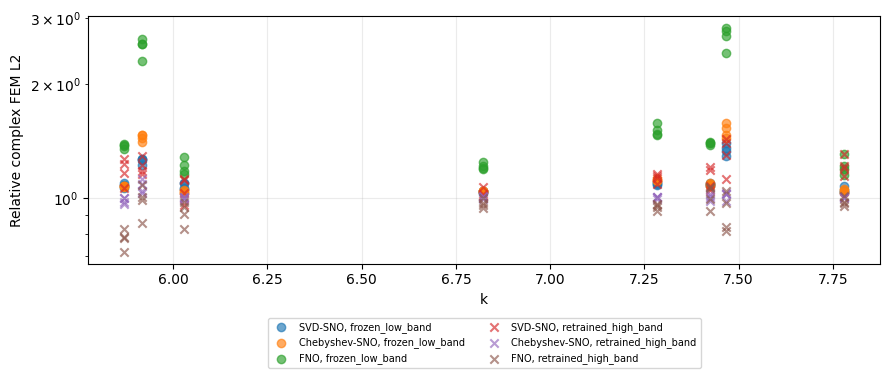

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for regime, marker in [('frozen_low_band', 'o'), ('retrained_high_band', 'x')]:
    for method in ['SVD-SNO', 'Chebyshev-SNO', 'FNO']:
        selected = [r for r in rows if r['regime'] == regime and r['method'] == method]
        ax.scatter([r['k'] for r in selected], [r['error_fem_l2'] for r in selected],
                   marker=marker, alpha=.65, label=f'{method}, {regime}')
ax.set(yscale='log', xlabel='k', ylabel='Relative complex FEM L2')
ax.legend(fontsize=7, ncol=2, loc='upper center', bbox_to_anchor=(.5, -.20))
ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT / 'frequency_errors.png', dpi=160)
plt.show()


Интерпретация: frozen error содержит frequency extrapolation и для SVD — ошибку переноса замороженного базиса. Retrained error проверяет другую обученную полосу при том же небольшом budget. Ошибка относительно fine FEM не учитывает всю ошибку FEM относительно непрерывной PDE; для неё отдельно смотрите refinement. Если rank/modes cap недостаточен, увеличение числа эпох не устраняет ограничение представления. Одна seed-серия на 48 средах — пилотное исследование, не доказательство высокочастотной точности.
